#Project:
##Chronic Kidney Disease Prediction Using Machine Learning with Comprehensive Feature Engineering

##Notebook overview
This notebook explores and demonstrates preprocessing and feature-engineering techniques on the UCI Chronic Kidney Disease dataset.
###Workflow:
 load and inspect the data → analyze missing values and distributions → compare imputation approaches → encode categories → inspect outliers → create age groups → demonstrate scaling and a log transformation.

###Colab Link
[click here](https://colab.research.google.com/drive/1f-IvQElPbFQYy4wkDC_I8X41cblNlfG_?usp=sharing)

###Github Link
[click here](https://github.com/siddheshmane18/AIML_SEM5)

##1. Import libraries and load the dataset
Purpose: Install/import the UCI repository helper and retrieve the Chronic Kidney Disease dataset (UCI dataset ID 336). X stores the input features, y stores the target, and pd.concat combines them into df for inspection.

In [1]:
!pip install -q ucimlrepo
# Import required libraries
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

# Load the Chronic Kidney Disease dataset from UCI
ckd = fetch_ucirepo(id=336)

# Separate features and target
X = ckd.data.features
y = ckd.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")

Dataset loaded successfully!


###1.1 Check the dataset dimensions

In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 400
Number of columns: 25
Dataset shape: (400, 25)


###1.2 Preview the records

In [3]:
display(df.head())

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


###1.3 Inspect column names and data types

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Column names:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

Data types:
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc       object
pc        object
pcc       object
ba        object
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn       object
dm        object
cad       object
appet     object
pe        object
ane       object
class     object
dtype: object


###1.4 Quantify missing data

In [5]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Display columns with the most missing values first
display(
    missing_summary.sort_values(
        by="Missing Count",
        ascending=False
    )
)

,Missing Count,Missing Percentage
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


###1.5 Inspect the target distribution

This cell finds the target column name from y, then counts each target label and calculates its percentage. dropna=False ensures missing labels would also be counted.

In [6]:
target_column = y.columns[0]

print("Target column:", target_column)
print("\nTarget class counts:")
print(df[target_column].value_counts(dropna=False))

print("\nTarget class percentages:")
print(
    (df[target_column].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Target column: class

Target class counts:
class
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

Target class percentages:
class
ckd       62.0
notckd    37.5
ckd\t      0.5
Name: proportion, dtype: float64


###1.6 Descriptive statistics for numerical features
select_dtypes(include=['number']) selects numeric columns. <br>
describe().T calculates count, mean, standard deviation, minimum, quartiles, and maximum, then transposes the table so each feature occupies a row.

In [7]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["number"]).columns

# Generate descriptive statistics
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,391.0,51.483376,17.169714,2.000,42.00,55.00,64.50,90.000
bp,388.0,76.469072,13.683637,50.000,70.00,80.00,80.00,180.000
sg,353.0,1.017408,0.005717,1.005,1.01,1.02,1.02,1.025
al,354.0,1.016949,1.352679,0.000,0.00,0.00,2.00,5.000
su,351.0,0.450142,1.099191,0.000,0.00,0.00,0.00,5.000
bgr,356.0,148.036517,79.281714,22.000,99.00,121.00,163.00,490.000
bu,381.0,57.425722,50.503006,1.500,27.00,42.00,66.00,391.000
sc,383.0,3.072454,5.741126,0.400,0.90,1.30,2.80,76.000
sod,313.0,137.528754,10.408752,4.500,135.00,138.00,142.00,163.000
pot,312.0,4.627244,3.193904,2.500,3.80,4.40,4.90,47.000


###1.7 Calculate missing percentages for numerical features

In [8]:
# Calculate missing-value percentages for each numerical feature
missing_percent = (
    df[numerical_columns].isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percent.round(2))

rbcc    32.75
wbcc    26.50
pot     22.00
sod     21.75
pcv     17.75
hemo    13.00
su      12.25
sg      11.75
al      11.50
bgr     11.00
bu       4.75
sc       4.25
bp       3.00
age      2.25
dtype: float64


###1.8 Visualize numerical missingness

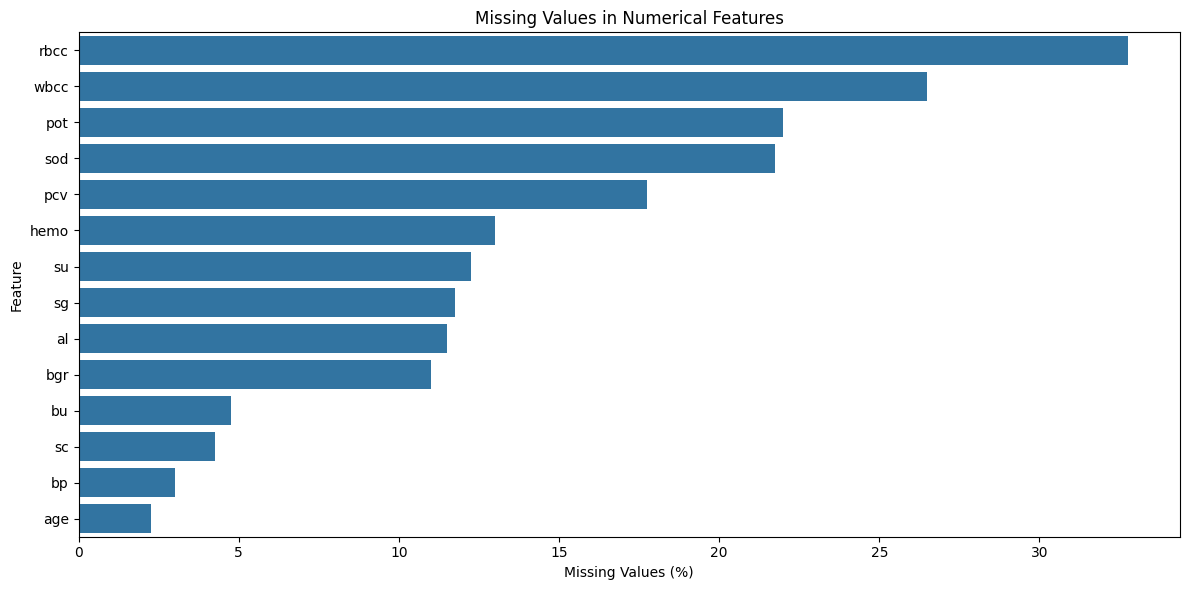

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Values in Numerical Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

###1.9 Boxplots to screen numerical features for outliers

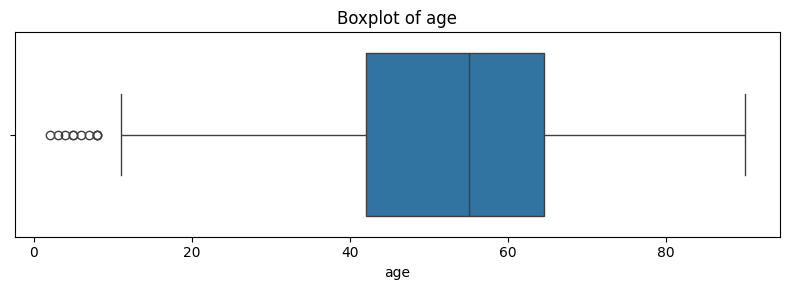

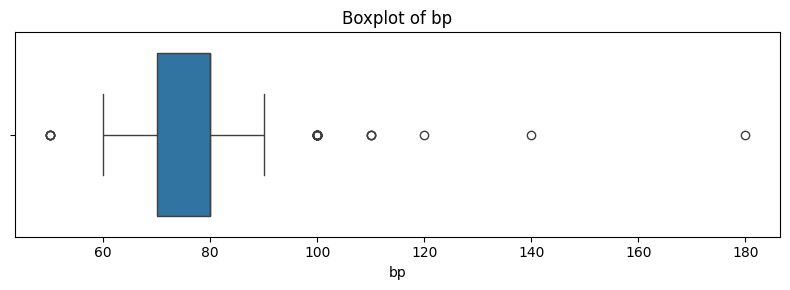

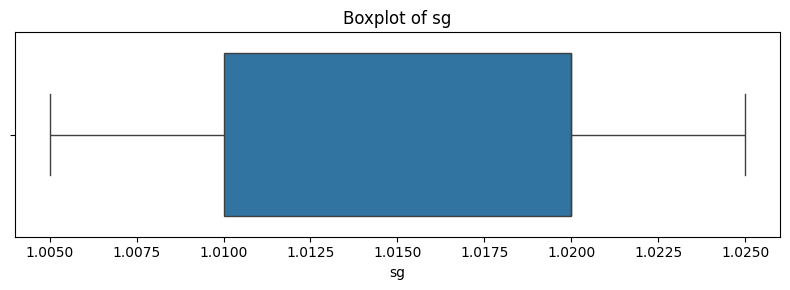

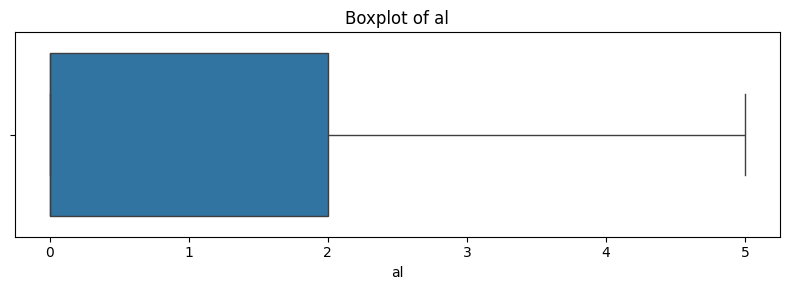

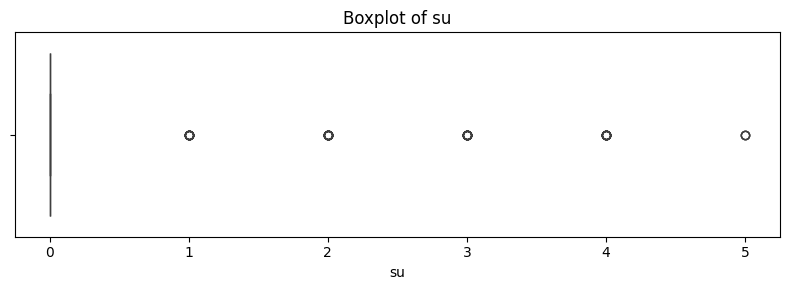

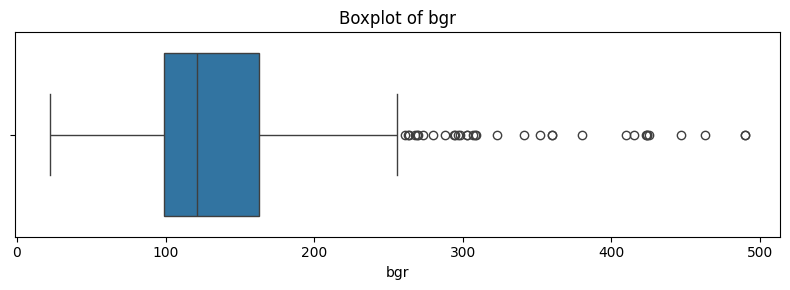

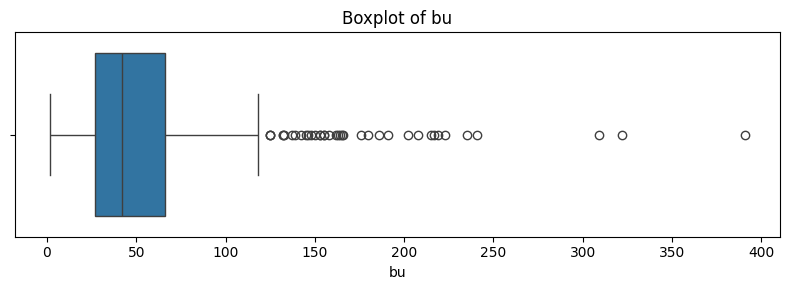

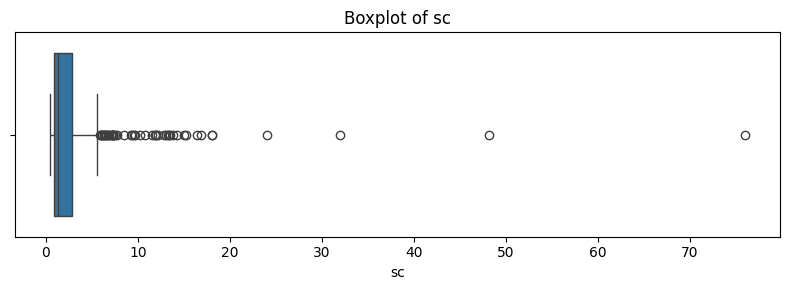

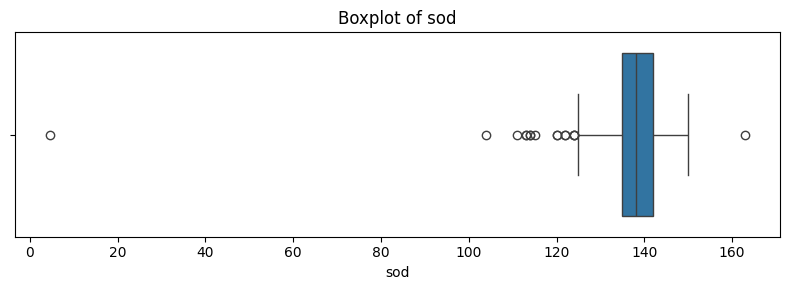

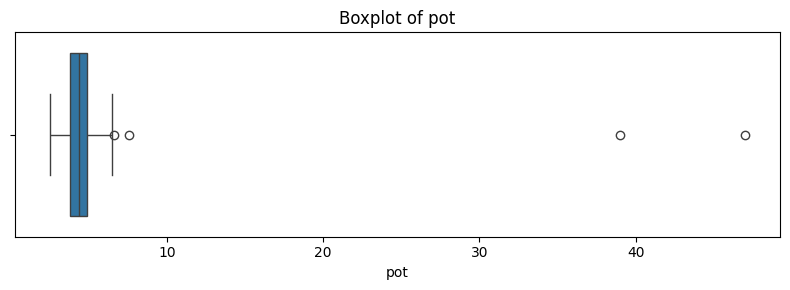

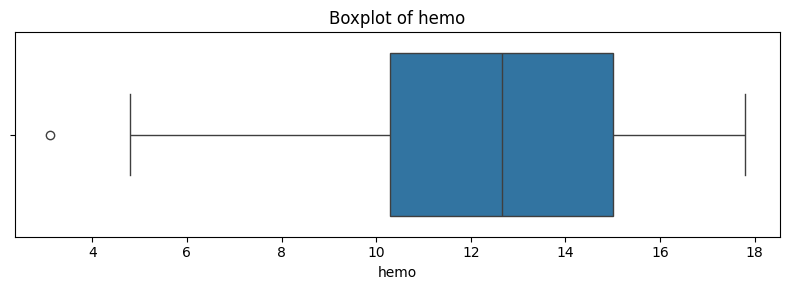

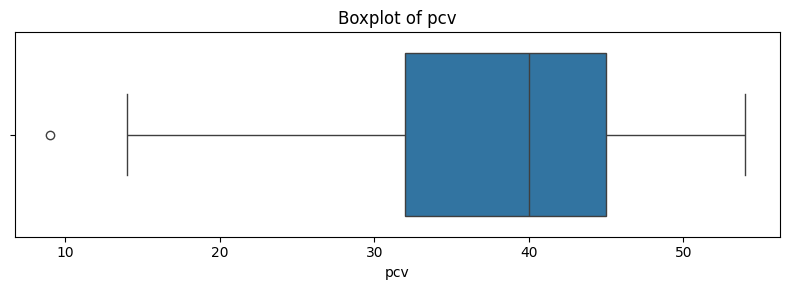

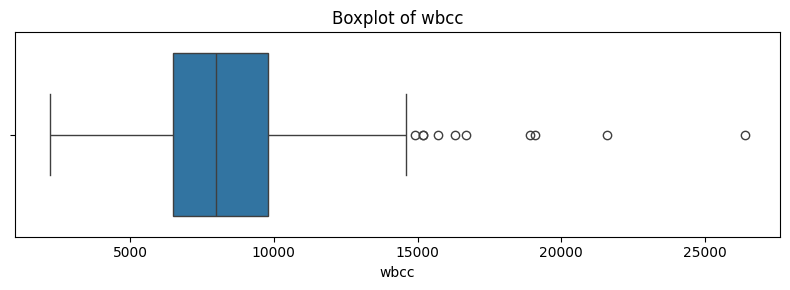

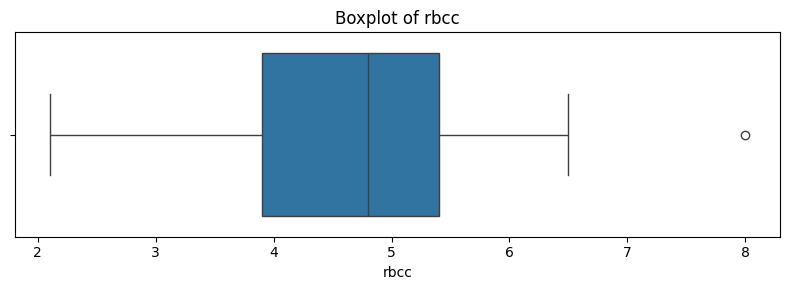

In [10]:
# Plot boxplots for numerical features
for col in numerical_columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

###1.10 Flag potential outliers using the IQR rule
For each selected feature, the code calculates Q1, Q3, and IQR = Q3 − Q1. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are listed as potential outliers.

In [11]:
features_to_inspect = ["bp", "bgr", "bu", "sc", "sod", "pot"]

for col in features_to_inspect:
    print(f"\n{'=' * 45}")
    print(f"Feature: {col}")

    lower = df[col].quantile(0.25)
    upper = df[col].quantile(0.75)
    iqr = upper - lower

    lower_bound = lower - 1.5 * iqr
    upper_bound = upper + 1.5 * iqr

    potential_outliers = df.loc[
        (df[col] < lower_bound) | (df[col] > upper_bound),
        [col, "class"]
    ]

    print(f"Lower IQR bound: {lower_bound:.3f}")
    print(f"Upper IQR bound: {upper_bound:.3f}")
    print(f"Potential outlier count: {len(potential_outliers)}")

    display(potential_outliers.sort_values(col))


Feature: bp
Lower IQR bound: 55.000
Upper IQR bound: 95.000
Potential outlier count: 36


,bp,class
1,50.0,ckd
186,50.0,ckd
175,50.0,ckd
131,50.0,ckd
229,50.0,ckd
8,100.0,ckd
18,100.0,ckd
24,100.0,ckd
73,100.0,ckd
87,100.0,ckd



Feature: bgr
Lower IQR bound: 3.000
Upper IQR bound: 259.000
Potential outlier count: 34


,bgr,class
175,261.0,ckd
18,263.0,ckd
27,264.0,ckd
137,268.0,ckd
231,269.0,ckd
35,270.0,ckd
153,273.0,ckd
90,280.0,ckd
147,288.0,ckd
111,294.0,ckd



Feature: bu
Lower IQR bound: -31.500
Upper IQR bound: 124.500
Potential outlier count: 38


,bu,class
126,125.0,ckd
127,125.0,ckd
133,125.0,ckd
154,132.0,ckd
210,132.0,ckd
177,133.0,ckd
184,137.0,ckd
76,139.0,ckd
58,142.0,ckd
142,145.0,ckd


... (2 outputs left out)


Feature: sod
Lower IQR bound: 124.500
Upper IQR bound: 152.500
Potential outlier count: 16


,sod,class
21,4.5,ckd
6,104.0,ckd
3,111.0,ckd
175,113.0,ckd
193,113.0,ckd
229,114.0,ckd
9,114.0,ckd
171,115.0,ckd
246,120.0,ckd
242,120.0,ckd



Feature: pot
Lower IQR bound: 2.150
Upper IQR bound: 6.550
Potential outlier count: 4


,pot,class
60,6.6,ckd
84,7.6,ckd
61,39.0,ckd
128,47.0,ckd


###1.11 Inspect categories
This cell identifies columns stored as object or category and prints the frequency of every value, including missing entries. It helps reveal rare categories, missingness, and inconsistent spelling or whitespace.

In [12]:
# Select categorical columns, including the target
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    print(f"\n{'=' * 40}")
    print(f"Feature: {col}")

    print(df[col].value_counts(dropna=False))


Feature: rbc
rbc
normal      201
NaN         152
abnormal     47
Name: count, dtype: int64

Feature: pc
pc
normal      259
abnormal     76
NaN          65
Name: count, dtype: int64

Feature: pcc
pcc
notpresent    354
present        42
NaN             4
Name: count, dtype: int64

Feature: ba
ba
notpresent    374
present        22
NaN             4
Name: count, dtype: int64

Feature: htn
htn
no     251
yes    147
NaN      2
Name: count, dtype: int64

Feature: dm
dm
no      260
yes     137
NaN       2
\tno      1
Name: count, dtype: int64

Feature: cad
cad
no     364
yes     34
NaN      2
Name: count, dtype: int64

Feature: appet
appet
good    317
poor     82
NaN       1
Name: count, dtype: int64

Feature: pe
pe
no     323
yes     76
NaN      1
Name: count, dtype: int64

Feature: ane
ane
no     339
yes     60
NaN      1
Name: count, dtype: int64

Feature: class
class
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


###1.12 Plot categorical distributions

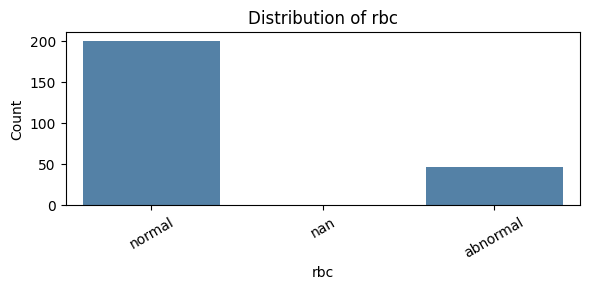

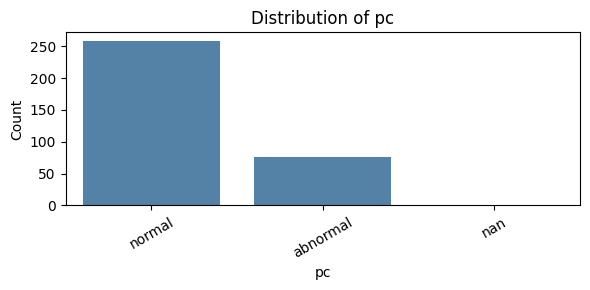

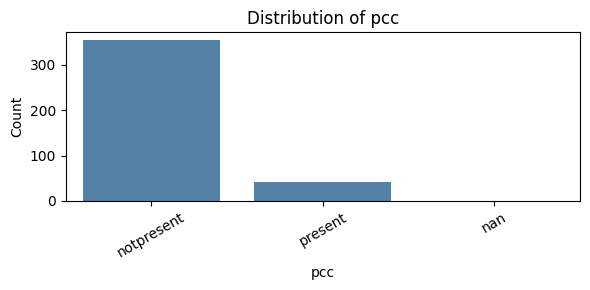

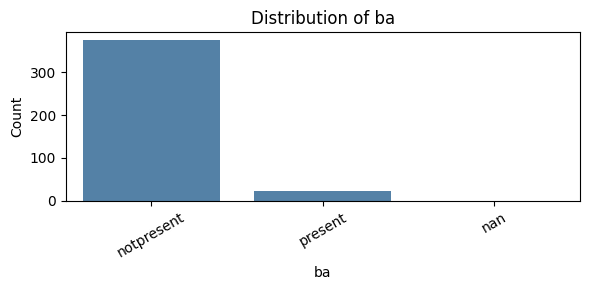

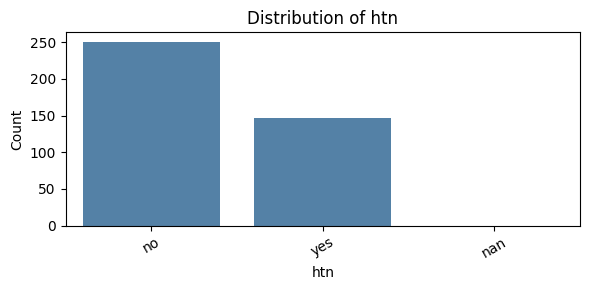

/tmp/ipykernel_2013/2062257127.py:25: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


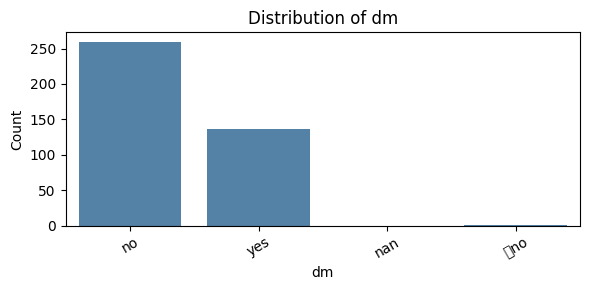

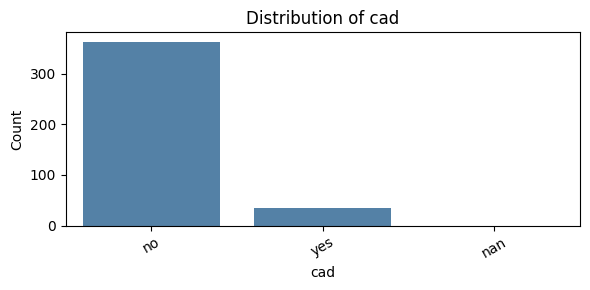

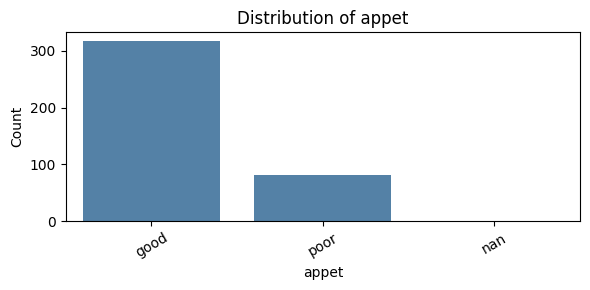

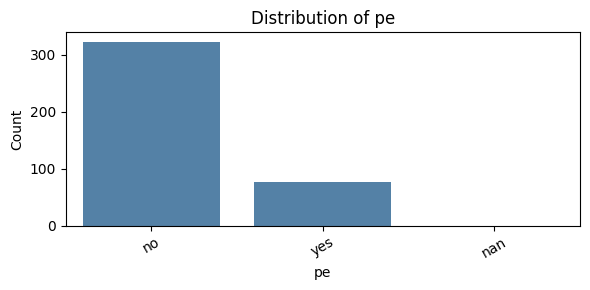

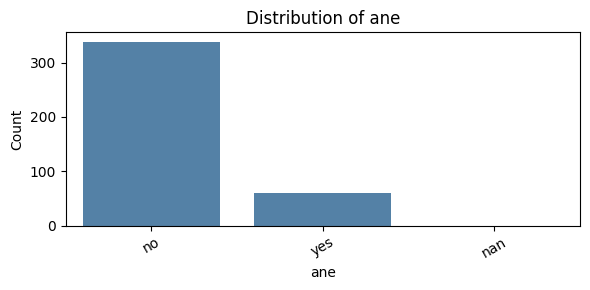

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude the target from predictor plots
categorical_features = [
    col for col in categorical_columns
    if col != "class"
]

for col in categorical_features:
    plt.figure(figsize=(6, 3))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts(dropna=False).index,
        color="steelblue"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

###1.13 Review missingness across all columns
This cell builds a missing-count and missing-percentage table for every column and sorts it by missing percentage.

In [14]:
# Missing-value summary for every column
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


##2. Demonstrate imputation on a small example
This cell creates a tiny demonstration DataFrame with numeric columns (age, sc) and a categorical column (htn), each containing a missing value. It is a teaching example, separate from the CKD dataset.
Purpose: The small example makes it easier to see how mean, median, and mode imputation work.

In [15]:
import pandas as pd
import numpy as np

demo = pd.DataFrame({
    "age": [25, 30, 35, np.nan, 40],
    "sc": [0.8, 1.0, 1.2, np.nan, 10.0],
    "htn": ["no", "no", "yes", np.nan, "yes"]
})

print("Original demonstration dataset:")
display(demo)

Original demonstration dataset:


,age,sc,htn
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,NaN,NaN,NaN
4,40.0,10.0,yes


###2.1 Compare mean, median, and mode imputation
Three independent copies of the example are created. Missing numeric values are filled using the column mean or median, while the missing categorical value is filled with the most frequent category (mode).

In [16]:
# Create a separate copy for mean imputation
demo_mean = demo.copy()

demo_mean["age"] = demo_mean["age"].fillna(
    demo_mean["age"].mean()
)

demo_mean["sc"] = demo_mean["sc"].fillna(
    demo_mean["sc"].mean()
)

print("Mean imputation:")
display(demo_mean)


# Create a separate copy for median imputation
demo_median = demo.copy()

demo_median["age"] = demo_median["age"].fillna(
    demo_median["age"].median()
)

demo_median["sc"] = demo_median["sc"].fillna(
    demo_median["sc"].median()
)

print("Median imputation:")
display(demo_median)


# Create a separate copy for mode imputation
demo_mode = demo.copy()

demo_mode["htn"] = demo_mode["htn"].fillna(
    demo_mode["htn"].mode()[0]
)

print("Mode imputation:")
display(demo_mode)

Mean imputation:


,age,sc,htn
0,25.0,0.80,no
1,30.0,1.00,no
2,35.0,1.20,yes
3,32.5,3.25,NaN
4,40.0,10.00,yes


Median imputation:


,age,sc,htn
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,32.5,1.1,NaN
4,40.0,10.0,yes


Mode imputation:


,age,sc,htn
0,25.0,0.8,no
1,30.0,1.0,no
2,35.0,1.2,yes
3,NaN,NaN,no
4,40.0,10.0,yes


###2.2 Prepare separate datasets for imputation comparison
The original DataFrame is copied and three additional copies are made for mean, median, and mode experiments. The shape prints verify that copying did not change the number of rows or columns.

In [17]:
# Preserve the cleaned dataset before imputation
df_before_imputation = df.copy(deep=True)

# Create separate datasets for comparison
df_mean_imputed = df.copy(deep=True)
df_median_imputed = df.copy(deep=True)
df_mode_imputed = df.copy(deep=True)

print("Original dataset:", df.shape)
print("Mean-imputation dataset:", df_mean_imputed.shape)
print("Median-imputation dataset:", df_median_imputed.shape)
print("Mode-imputation dataset:", df_mode_imputed.shape)

Original dataset: (400, 25)
Mean-imputation dataset: (400, 25)
Median-imputation dataset: (400, 25)
Mode-imputation dataset: (400, 25)


###2.3 Apply mean imputation to numerical columns
Each numerical column's missing entries are replaced by that column's mean. The final print reports remaining missing values in those numeric columns.

In [18]:
# Identify numerical predictor columns
numerical_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Apply mean imputation to numerical features
for col in numerical_features:
    df_mean_imputed[col] = df_mean_imputed[col].fillna(
        df_mean_imputed[col].mean()
    )

print("Missing values after mean imputation:")
print(df_mean_imputed[numerical_features].isnull().sum())

Missing values after mean imputation:
age     0
bp      0
sg      0
al      0
su      0
bgr     0
bu      0
sc      0
sod     0
pot     0
hemo    0
pcv     0
wbcc    0
rbcc    0
dtype: int64


###2.4 Apply median imputation to numerical columns

In [19]:
# Apply median imputation to numerical features
for col in numerical_features:
    df_median_imputed[col] = df_median_imputed[col].fillna(
        df_median_imputed[col].median()
    )

print("Missing values after median imputation:")
print(df_median_imputed[numerical_features].isnull().sum())

Missing values after median imputation:
age     0
bp      0
sg      0
al      0
su      0
bgr     0
bu      0
sc      0
sod     0
pot     0
hemo    0
pcv     0
wbcc    0
rbcc    0
dtype: int64


###2.5 Apply mode imputation to categorical predictors
The code identifies object-type predictors other than class and fills each missing entry with that column's most frequent non-missing category.

In [20]:
# Identify categorical predictor columns
categorical_features = [
    col for col in df.select_dtypes(include=["object"]).columns
    if col != "class"
]

# Apply mode imputation to categorical predictors
for col in categorical_features:
    mode_values = df_mode_imputed[col].mode(dropna=True)

    if not mode_values.empty:
        df_mode_imputed[col] = df_mode_imputed[col].fillna(
            mode_values.iloc[0]
        )

print("Missing values after categorical mode imputation:")
print(df_mode_imputed[categorical_features].isnull().sum())

Missing values after categorical mode imputation:
rbc      0
pc       0
pcc      0
ba       0
htn      0
dm       0
cad      0
appet    0
pe       0
ane      0
dtype: int64


###2.6 Compare missingness before and after imputation
The table compares the number of missing entries in the original data and the three imputed copies. It is a verification step for the preceding experiments.

In [21]:
comparison = pd.DataFrame({
    "Before Imputation": df_before_imputation.isnull().sum(),
    "Mean Imputation": df_mean_imputed.isnull().sum(),
    "Median Imputation": df_median_imputed.isnull().sum(),
    "Mode Imputation": df_mode_imputed.isnull().sum()
})

display(comparison)

,Before Imputation,Mean Imputation,Median Imputation,Mode Imputation
age,9,0,0,9
bp,12,0,0,12
sg,47,0,0,47
al,46,0,0,46
su,49,0,0,49
rbc,152,152,152,0
pc,65,65,65,0
pcc,4,4,4,0
ba,4,4,4,0
bgr,44,0,0,44


##3. Create a feature-engineering demonstration dataset
The code makes a separate copy named df_encoded_demo, imputes numerical predictors with medians and categorical predictors with modes, and reports the remaining predictor missingness and shape.

In [22]:
# Start with the cleaned dataset
df_encoded_demo = df.copy(deep=True)

# Identify numerical predictor columns
numerical_features = df_encoded_demo.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical predictor columns
categorical_features = [
    col
    for col in df_encoded_demo.select_dtypes(include=["object"]).columns
    if col != "class"
]

# Median imputation for numerical features
for col in numerical_features:
    df_encoded_demo[col] = df_encoded_demo[col].fillna(
        df_encoded_demo[col].median()
    )

# Mode imputation for categorical features
for col in categorical_features:
    mode_values = df_encoded_demo[col].mode(dropna=True)

    if not mode_values.empty:
        df_encoded_demo[col] = df_encoded_demo[col].fillna(
            mode_values.iloc[0]
        )

print("Remaining missing predictor values:",
      df_encoded_demo[numerical_features + categorical_features]
      .isnull().sum().sum())

print("Dataset shape:", df_encoded_demo.shape)

Remaining missing predictor values: 0
Dataset shape: (400, 25)


###3.1 Normalize whitespace in categorical strings

In [23]:
# Remove leading/trailing whitespace and tab characters
for col in df_encoded_demo.select_dtypes(include="object").columns:
    df_encoded_demo[col] = df_encoded_demo[col].str.strip()

# Check the dm column
print(df_encoded_demo["dm"].value_counts(dropna=False))

dm
no     263
yes    137
Name: count, dtype: int64


###3.2 Encode binary categorical predictors
The dictionary defines explicit mappings from text labels to numeric values (for example, no → 0 and yes → 1). The loop applies each mapping, and head() previews the resulting table.

In [24]:
# Define explicit mappings for binary categorical features
binary_mappings = {
    "rbc": {"normal": 0, "abnormal": 1},
    "pc": {"normal": 0, "abnormal": 1},
    "pcc": {"notpresent": 0, "present": 1},
    "ba": {"notpresent": 0, "present": 1},
    "htn": {"no": 0, "yes": 1},
    "dm": {"no": 0, "yes": 1},
    "cad": {"no": 0, "yes": 1},
    "appet": {"poor": 0, "good": 1},
    "pe": {"no": 0, "yes": 1},
    "ane": {"no": 0, "yes": 1}
}

# Apply the mappings
for col, mapping in binary_mappings.items():
    df_encoded_demo[col] = df_encoded_demo[col].map(mapping)

print("Categorical encoding completed.")

display(df_encoded_demo.head())

Categorical encoding completed.


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,0,0,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,1,0,0,ckd
1,7.0,50.0,1.020,4.0,0.0,0,0,0,0,121.0,...,38.0,6000.0,4.8,0,0,0,1,0,0,ckd
2,62.0,80.0,1.010,2.0,3.0,0,0,0,0,423.0,...,31.0,7500.0,4.8,0,1,0,0,0,1,ckd
3,48.0,70.0,1.005,4.0,0.0,0,1,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,0,1,1,ckd
4,51.0,80.0,1.010,2.0,0.0,0,0,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,1,0,0,ckd


###3.3 Verify encoded category frequencies

In [25]:
encoded_features = list(binary_mappings.keys())

for col in encoded_features:
    print(f"\n{col}:")
    print(df_encoded_demo[col].value_counts(dropna=False))


rbc:
rbc
0    353
1     47
Name: count, dtype: int64

pc:
pc
0    324
1     76
Name: count, dtype: int64

pcc:
pcc
0    358
1     42
Name: count, dtype: int64

ba:
ba
0    378
1     22
Name: count, dtype: int64

htn:
htn
0    253
1    147
Name: count, dtype: int64

dm:
dm
0    263
1    137
Name: count, dtype: int64

cad:
cad
0    366
1     34
Name: count, dtype: int64

appet:
appet
1    318
0     82
Name: count, dtype: int64

pe:
pe
0    324
1     76
Name: count, dtype: int64

ane:
ane
0    340
1     60
Name: count, dtype: int64


###3.4 Validate mapped values
For each encoded predictor, the code searches for non-missing values that are not among the mapping's allowed numeric values.

In [26]:
for col, mapping in binary_mappings.items():
    unmapped = df_encoded_demo.loc[
        df_encoded_demo[col].notna()
        & ~df_encoded_demo[col].isin(mapping.values()),
        col
    ].unique()

    if len(unmapped) > 0:
        print(f"{col}: unexpected encoded values found:", unmapped)


###3.5 Encode the target label
The target is mapped separately: notckd → 0 and ckd → 1. Keeping the target mapping explicit makes the class meaning clear.

In [27]:
# Encode the target separately
target_mapping = {
    "notckd": 0,
    "ckd": 1
}

df_encoded_demo["class"] = df_encoded_demo["class"].map(
    target_mapping
)

print(df_encoded_demo["class"].value_counts(dropna=False))

class
1    250
0    150
Name: count, dtype: int64


###3.6 Verify the encoded demonstration dataset
The cell checks dataset shape, total remaining missing values, data types, and target balance after encoding

In [28]:
print("Dataset shape:", df_encoded_demo.shape)

print("\nRemaining missing values:")
print(df_encoded_demo.isnull().sum().sum())

print("\nData types:")
print(df_encoded_demo.dtypes)

print("\nTarget distribution:")
print(df_encoded_demo["class"].value_counts())

Dataset shape: (400, 25)

Remaining missing values:
0

Data types:
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc        int64
pc         int64
pcc        int64
ba         int64
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn        int64
dm         int64
cad        int64
appet      int64
pe         int64
ane        int64
class      int64
dtype: object

Target distribution:
class
1    250
0    150
Name: count, dtype: int64


##4. Outlier analysis after imputation
This boxplot visualizes the distribution of bgr (random blood glucose) in the demonstration dataset. Boxplots highlight the median, quartiles, and potential extreme observations.<br><br>Points beyond the whiskers are potential outliers according to the boxplot rule.

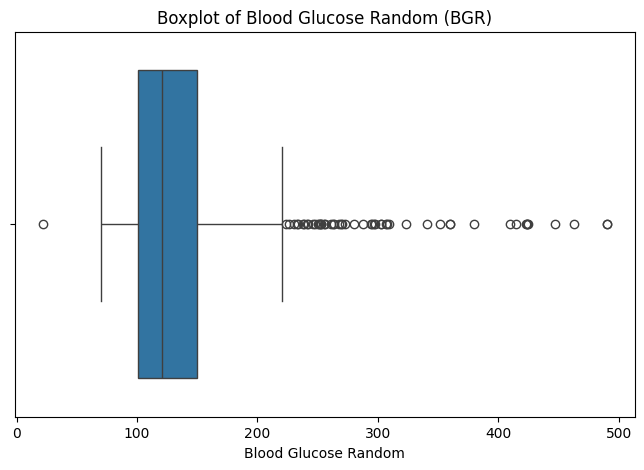

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(x=df_encoded_demo["bgr"])

plt.title("Boxplot of Blood Glucose Random (BGR)")
plt.xlabel("Blood Glucose Random")
plt.show()

###4.1 Detect BGR outliers using the IQR method
The code calculates Q1, Q3, IQR and the conventional 1.5-IQR bounds, then lists rows outside those bounds.

In [30]:
Q1 = df_encoded_demo["bgr"].quantile(0.25)
Q3 = df_encoded_demo["bgr"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df_encoded_demo[
    (df_encoded_demo["bgr"] < lower_bound) |
    (df_encoded_demo["bgr"] > upper_bound)
]

print("\nNumber of potential outliers:", len(outliers))
print("\nPotential outlier values:")
print(outliers["bgr"].sort_values())

Q1: 101.0
Q3: 150.0
IQR: 49.0
Lower bound: 27.5
Upper bound: 223.5

Number of potential outliers: 53

Potential outlier values:
173     22.0
128    224.0
103    226.0
207    230.0
109    233.0
180    234.0
219    238.0
189    239.0
229    241.0
154    242.0
53     246.0
221    248.0
69     250.0
88     251.0
198    252.0
58     253.0
212    253.0
210    255.0
140    256.0
175    261.0
18     263.0
27     264.0
137    268.0
231    269.0
35     270.0
153    273.0
90     280.0
147    288.0
111    294.0
93     295.0
107    297.0
99     298.0
223    303.0
159    303.0
168    307.0
125    308.0
172    309.0
120    323.0
208    341.0
184    352.0
81     360.0
70     360.0
11     380.0
7      410.0
86     415.0
2      423.0
158    424.0
248    424.0
67     425.0
170    447.0
244    463.0
10     490.0
225    490.0
Name: bgr, dtype: float64


Observed result: Q1 = 101, Q3 = 150, IQR = 49, with bounds of 27.5 and 223.5. The code flags 53 records. Some values may be valid clinical observations; investigate rather than deleting them automatically

###4.2 Detect BGR outliers using three standard deviations
This cell defines bounds at the mean minus/plus three standard deviations and lists values outside them. It is a second screening method, different from the IQR method.

In [31]:
import numpy as np

# Select the feature
column = "bgr"

# Calculate mean and standard deviation
mean_value = df_encoded_demo[column].mean()
std_value = df_encoded_demo[column].std()

# Calculate bounds
lower_bound = mean_value - 3 * std_value
upper_bound = mean_value + 3 * std_value

# Identify potential outliers
outliers_std = df_encoded_demo[
    (df_encoded_demo[column] < lower_bound) |
    (df_encoded_demo[column] > upper_bound)
]

print("Feature:", column)
print("Mean:", mean_value)
print("Standard deviation:", std_value)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers_std))
print("\nPotential outlier values:")
print(outliers_std[column].sort_values())

Feature: bgr
Mean: 145.0625
Standard deviation: 75.26077367317394
Lower bound: -80.71982101952182
Upper bound: 370.8448210195218
Number of potential outliers: 11

Potential outlier values:
11     380.0
7      410.0
86     415.0
2      423.0
158    424.0
248    424.0
67     425.0
170    447.0
244    463.0
10     490.0
225    490.0
Name: bgr, dtype: float64


Observed result: The mean is about 145.06, standard deviation about 75.26, and the upper bound about 370.84. Eleven records are flagged above this upper bound. The standard-deviation method assumes a distribution where this rule is meaningful; BGR is skewed, so compare this result with the IQR approach.

##5. Create age groups (binning)
pd.cut converts continuous age values into four labelled intervals: Young, Young Adult, Middle-Aged, and Older Adult. The cell previews the assignments and counts records in each group.

In [32]:
# Create age groups
age_bins = [0, 18, 35, 55, 100]
age_labels = [
    "Young",
    "Young Adult",
    "Middle-Aged",
    "Older Adult"
]

df_encoded_demo["age_group"] = pd.cut(
    df_encoded_demo["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Display the results
print(df_encoded_demo[["age", "age_group"]].head(10))

print("\nAge group distribution:")
print(df_encoded_demo["age_group"].value_counts().sort_index())

    age    age_group
0  48.0  Middle-Aged
1   7.0        Young
2  62.0  Older Adult
3  48.0  Middle-Aged
4  51.0  Middle-Aged
5  60.0  Older Adult
6  68.0  Older Adult
7  24.0  Young Adult
8  52.0  Middle-Aged
9  53.0  Middle-Aged

Age group distribution:
age_group
Young           19
Young Adult     56
Middle-Aged    141
Older Adult    184
Name: count, dtype: int64


###5.1 Visualize age-group counts

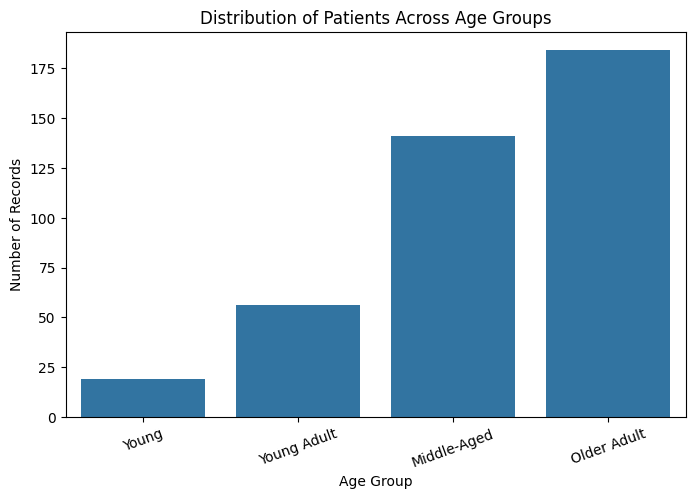

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_encoded_demo,
    x="age_group",
    order=age_labels
)

plt.title("Distribution of Patients Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.show()

###5.2 Examine target composition within age groups
pd.crosstab(..., normalize='index') * 100 calculates the percentage of each target class within each age group. The columns are renamed to make the encoded target meaning readable.

In [34]:
age_target_table = pd.crosstab(
    df_encoded_demo["age_group"],
    df_encoded_demo["class"],
    normalize="index"
) * 100

age_target_table = age_target_table.rename(
    columns={
        0: "Non-CKD (%)",
        1: "CKD (%)"
    }
)

print(age_target_table.round(2))

class        Non-CKD (%)  CKD (%)
age_group                        
Young              15.79    84.21
Young Adult        71.43    28.57
Middle-Aged        43.26    56.74
Older Adult        25.00    75.00


##6. Standardization with StandardScaler
The scaler transforms age, bgr, and sc to a scale centered around mean 0 with standard deviation 1. The transformed values are stored in a separate DataFrame so the original columns are preserved.

In [35]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for demonstration
features_to_scale = ["age", "bgr", "sc"]

# Create the scaler
standard_scaler = StandardScaler()

# Fit and transform the selected features
standard_scaled_values = standard_scaler.fit_transform(
    df_encoded_demo[features_to_scale]
)

# Store the scaled values in a separate DataFrame
df_standard_scaled = pd.DataFrame(
    standard_scaled_values,
    columns=features_to_scale,
    index=df_encoded_demo.index
)

print("Original values:")
print(df_encoded_demo[features_to_scale].head())

print("\nStandardized values:")
print(df_standard_scaled.head())

Original values:
    age    bgr   sc
0  48.0  121.0  1.2
1   7.0  121.0  0.8
2  62.0  423.0  1.8
3  48.0  117.0  3.8
4  51.0  106.0  1.4

Standardized values:
        age       bgr        sc
0 -0.210031 -0.320122 -0.319668
1 -2.627234 -0.320122 -0.390819
2  0.615355  3.697618 -0.212942
3 -0.210031 -0.373337  0.142813
4 -0.033163 -0.519679 -0.284093


###6.1 Min-Max scaling
MinMaxScaler rescales each selected feature to the interval [0, 1] using the observed minimum and maximum. The transformed values are stored separately and their minima/maxima are printed.

In [36]:
from sklearn.preprocessing import MinMaxScaler

# Create the scaler
minmax_scaler = MinMaxScaler()

# Fit and transform the selected features
minmax_scaled_values = minmax_scaler.fit_transform(
    df_encoded_demo[features_to_scale]
)

# Store the scaled values separately
df_minmax_scaled = pd.DataFrame(
    minmax_scaled_values,
    columns=features_to_scale,
    index=df_encoded_demo.index
)

print("Min-Max scaled values:")
print(df_minmax_scaled.head())

print("\nMinimum values after scaling:")
print(df_minmax_scaled.min())

print("\nMaximum values after scaling:")
print(df_minmax_scaled.max())

Min-Max scaled values:
        age       bgr        sc
0  0.522727  0.211538  0.010582
1  0.056818  0.211538  0.005291
2  0.681818  0.856838  0.018519
3  0.522727  0.202991  0.044974
4  0.556818  0.179487  0.013228

Minimum values after scaling:
age    0.0
bgr    0.0
sc     0.0
dtype: float64

Maximum values after scaling:
age    1.0
bgr    1.0
sc     1.0
dtype: float64


###6.2 Compare original, standardized, and Min-Max-scaled BGR
The three boxplots place the original BGR values, standardized values, and Min-Max-scaled values side by side.

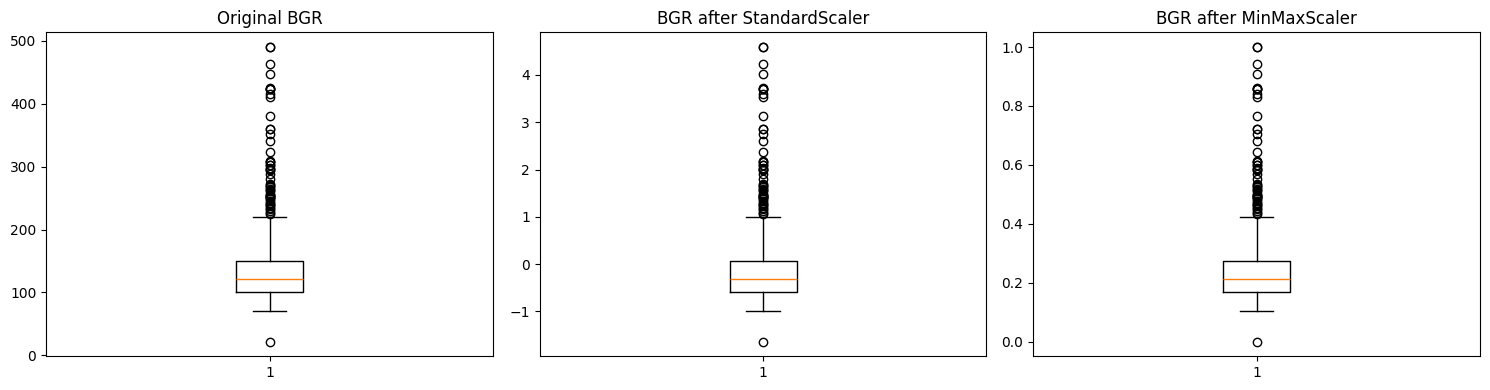

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].boxplot(df_encoded_demo["bgr"].dropna())
axes[0].set_title("Original BGR")

axes[1].boxplot(df_standard_scaled["bgr"].dropna())
axes[1].set_title("BGR after StandardScaler")

axes[2].boxplot(df_minmax_scaled["bgr"].dropna())
axes[2].set_title("BGR after MinMaxScaler")

plt.tight_layout()
plt.show()

##7. Examine BGR before log transformation
The histogram with a kernel-density estimate (KDE) shows the distribution of the original BGR feature. The KDE is a smoothed estimate of the distribution shape.

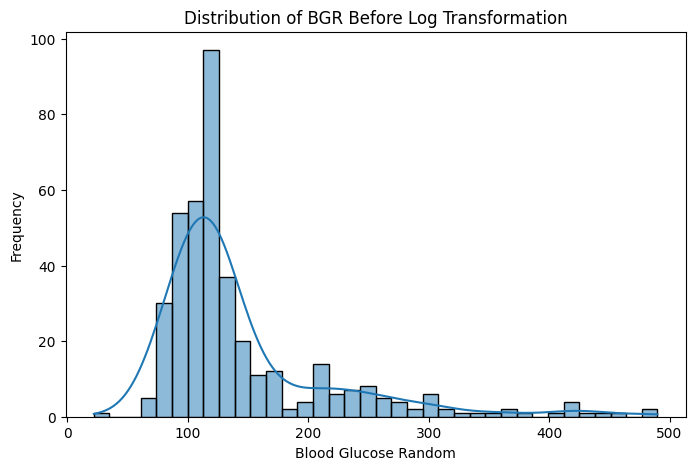

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_encoded_demo,
    x="bgr",
    kde=True
)

plt.title("Distribution of BGR Before Log Transformation")
plt.xlabel("Blood Glucose Random")
plt.ylabel("Frequency")

plt.show()

###7.1 Apply a log1p transformation
np.log1p(x) calculates log(1 + x) and is defined for non-negative values including zero. The transformed values are stored in a new column, bgr_log, so the original bgr remains available.

In [39]:
import numpy as np

df_encoded_demo["bgr_log"] = np.log1p(
    df_encoded_demo["bgr"]
)

print(
    df_encoded_demo[["bgr", "bgr_log"]].head(10)
)

     bgr   bgr_log
0  121.0  4.804021
1  121.0  4.804021
2  423.0  6.049733
3  117.0  4.770685
4  106.0  4.672829
5   74.0  4.317488
6  100.0  4.615121
7  410.0  6.018593
8  138.0  4.934474
9   70.0  4.262680


###7.2 Compare BGR distributions before and after transformation
The two histograms compare the original BGR distribution with bgr_log, using KDE curves to show the broad shape.

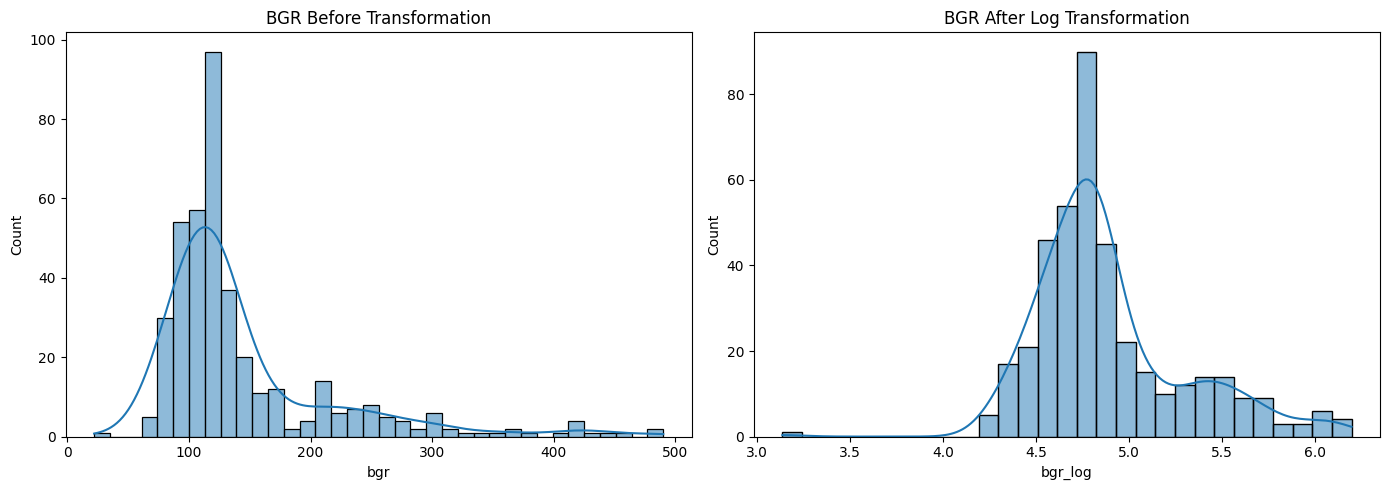

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_encoded_demo,
    x="bgr",
    kde=True,
    ax=axes[0]
)

axes[0].set_title("BGR Before Transformation")

sns.histplot(
    data=df_encoded_demo,
    x="bgr_log",
    kde=True,
    ax=axes[1]
)

axes[1].set_title("BGR After Log Transformation")

plt.tight_layout()
plt.show()

Interpretation: A log transform often compresses large values and reduces right skewness. Use the plotted distributions and the next skewness calculation to judge the effect in this dataset.

###7.3 Quantify skewness before and after transformation
Series.skew() calculates sample skewness. Positive values indicate a longer right tail; values closer to zero indicate less asymmetry, though zero does not guarantee a normal distribution.

In [41]:
original_skewness = df_encoded_demo["bgr"].skew()

transformed_skewness = df_encoded_demo["bgr_log"].skew()

print("Original BGR skewness:", original_skewness)

print("Transformed BGR skewness:", transformed_skewness)

Original BGR skewness: 2.2041428509602166
Transformed BGR skewness: 0.9117310004307808


Observed result: BGR skewness decreases from about 2.204 to 0.912 after log1p, indicating that the transformation reduces right skewness in this dataset.


# 8. Data Visualization Using Matplotlib

Data visualization helps us understand patterns, distributions, relationships,
and outliers in our dataset. In this section, we use Matplotlib to visualize
the data after performing data cleaning and feature engineering.



## 8.1 Histogram: BGR Distribution Before and After Log Transformation

### Purpose
To compare the distribution of the original BGR feature with the
log-transformed BGR feature and understand how log transformation
reduces skewness in the dataset.


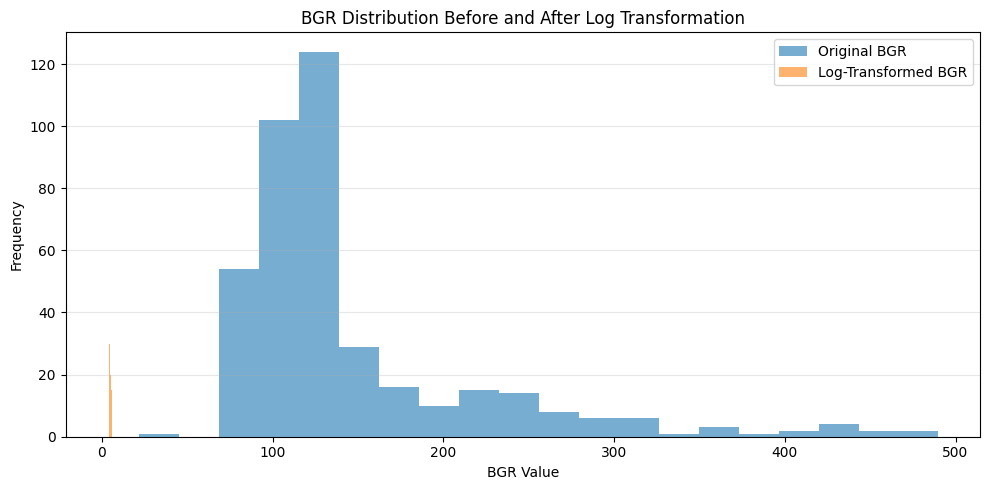

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df_encoded_demo["bgr"].dropna(),
         bins=20, alpha=0.6, label="Original BGR")

plt.hist(df_encoded_demo["bgr_log"].dropna(),
         bins=20, alpha=0.6, label="Log-Transformed BGR")

plt.title("BGR Distribution Before and After Log Transformation")
plt.xlabel("BGR Value")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Description: Histogram Before and After Log Transformation**

1. A histogram shows the distribution of numerical values by grouping them into intervals.
2. Here, it compares the original blood glucose random (BGR) values with their log1p-transformed values.
3. The X-axis shows original or transformed BGR values, while the Y-axis shows their frequency.
4. The reported skewness decreased from approximately 2.204 to 0.912, indicating reduced right skewness.
5. We use this comparison to assess how log transformation changes the distribution; reduced skewness does not necessarily mean the data is normally distributed.

## 8.2 Box Plot: Outlier Detection in Numerical Features
Purpose

The purpose of a box plot is to identify potential outliers and understand the distribution of numerical features in the processed dataset. It displays the median, quartiles, and spread of the data. We use this graph to check whether some numerical values are unusually high or low after data cleaning and feature engineering.

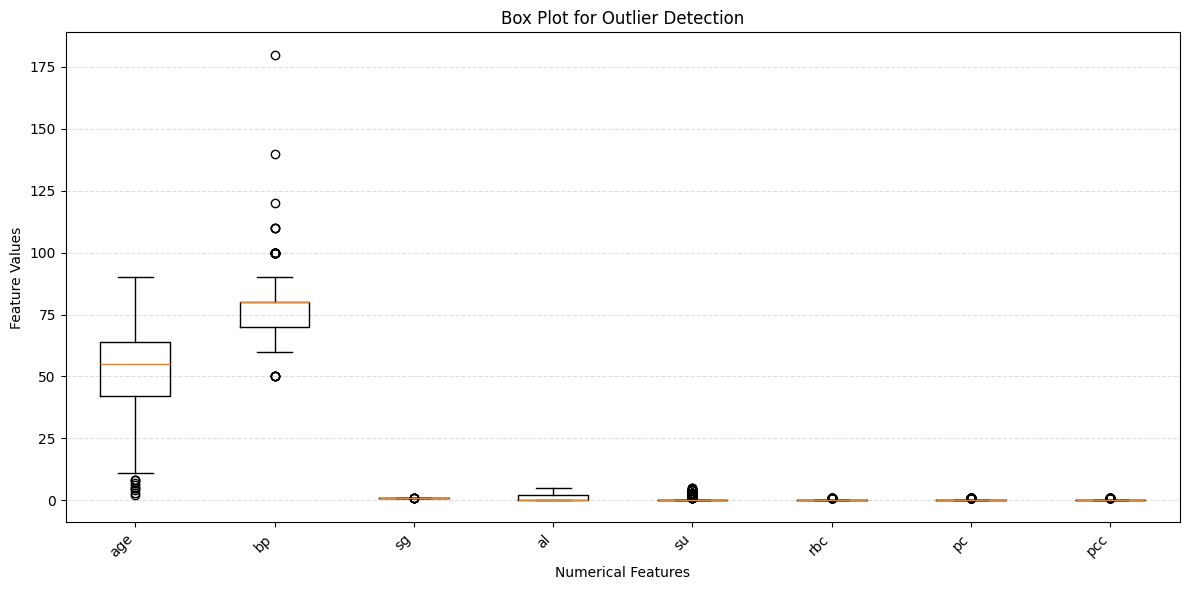

Dataset used: df_encoded_demo
Features plotted: ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc']


In [43]:

import pandas as pd
import matplotlib.pyplot as plt

# Find the existing processed DataFrame
data = None
data_name = None

for name in [
    "df_encoded_demo", "df_processed", "df_cleaned",
    "df_encoded", "df_scaled", "df_binned", "df"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        data = obj.copy()
        data_name = name
        break

if data is None:
    raise NameError(
        "Processed dataset not found. Run the earlier data "
        "preprocessing cells before running this graph."
    )

# Select numerical columns
numeric_data = data.select_dtypes(include="number")
numeric_data = numeric_data.dropna(axis=1, how="all")

if numeric_data.empty:
    raise ValueError("No numerical columns were found.")

# Remove columns that have no variation
numeric_data = numeric_data.loc[
    :, numeric_data.nunique(dropna=True) > 1
]

if numeric_data.empty:
    raise ValueError("No varying numerical columns are available.")

# Limit the plot to the first 8 numerical columns for readability
plot_data = numeric_data.iloc[:, :8].dropna()

# Create the box plot
plt.figure(figsize=(12, 6))
plt.boxplot(
    [plot_data[col].values for col in plot_data.columns],
    tick_labels=plot_data.columns,
    showfliers=True
)

plt.title("Box Plot for Outlier Detection")
plt.xlabel("Numerical Features")
plt.ylabel("Feature Values")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Dataset used:", data_name)
print("Features plotted:", plot_data.columns.tolist())


**Description: Box Plot for Outlier Detection**

1. A box plot summarizes the distribution of numerical data and highlights potential outliers.
2. The box represents the interquartile range, containing the middle 50% of observations.
3. The line inside the box represents the median value.
4. With the usual 1.5 × IQR rule, whiskers extend to the most extreme observations within the limits; points beyond them are potential outliers.
5. We use it to examine variability and unusual values, which should be investigated before removal.

## 8.3 Correlation Heatmap: Relationship Between Numerical Features

### Purpose

The purpose of a correlation heatmap is to understand the strength and direction of relationships between numerical features in the processed dataset. It helps identify features that move together, features that have opposite relationships, and potentially redundant features. This is useful during feature engineering and feature selection.

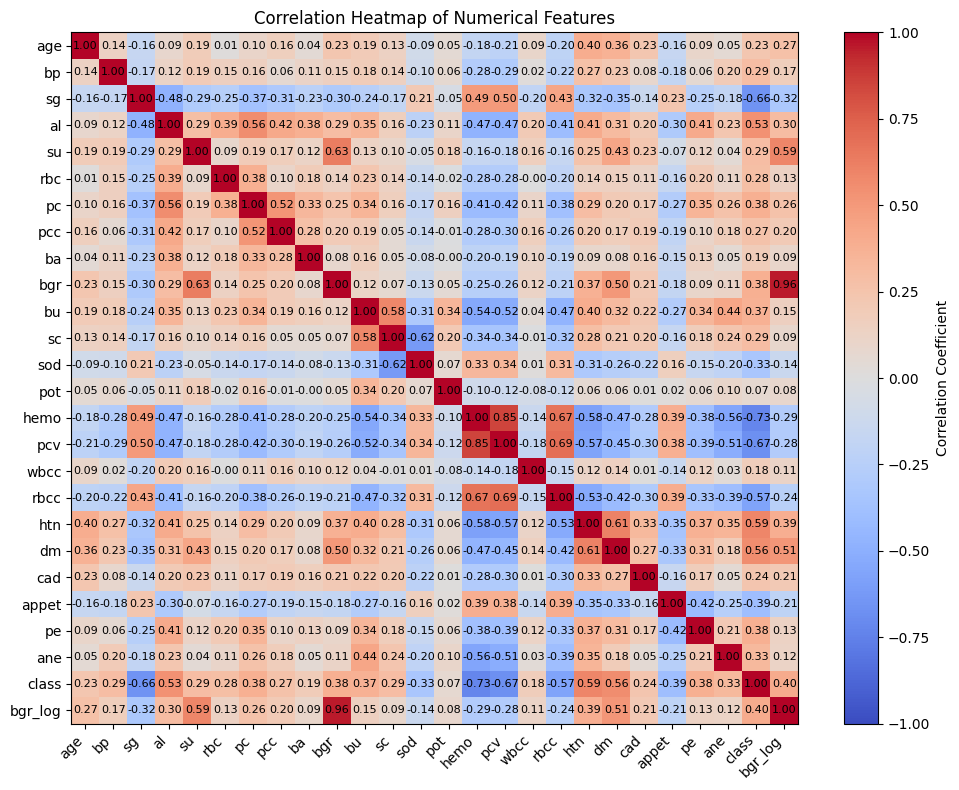

Dataset used: df_encoded_demo
Features included: ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class', 'bgr_log']


In [44]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Find the existing processed DataFrame
data = None
data_name = None

for name in [
    "df_encoded_demo", "df_processed", "df_cleaned",
    "df_encoded", "df_scaled", "df_binned", "df"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        data = obj.copy()
        data_name = name
        break

if data is None:
    raise NameError(
        "Processed dataset not found. Run the earlier data "
        "preprocessing cells before running this graph."
    )

# Select numerical features
numeric_data = data.select_dtypes(include="number")
numeric_data = numeric_data.dropna(axis=1, how="all")

# Keep columns with at least two distinct values
numeric_data = numeric_data.loc[
    :, numeric_data.nunique(dropna=True) > 1
]

if numeric_data.shape[1] < 2:
    raise ValueError(
        "At least two varying numerical features are required."
    )

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Plot heatmap using Matplotlib
fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(
    correlation_matrix.columns, rotation=45, ha="right"
)
ax.set_yticklabels(correlation_matrix.columns)

# Display correlation values inside the heatmap
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center", fontsize=8
            )

plt.colorbar(image, ax=ax, label="Correlation Coefficient")
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("Dataset used:", data_name)
print("Features included:", numeric_data.columns.tolist())


**Description: Correlation Heatmap**

1. A correlation heatmap displays correlations between numerical features using colors.
2. Each cell represents the correlation coefficient between a pair of features.
3. Values near +1 indicate a strong positive linear relationship; values near −1 indicate a strong negative linear relationship.
4. Values near 0 indicate a weak or absent linear relationship, although nonlinear relationships may still exist.
5. We use it to identify potentially redundant features and support feature selection; correlation does not establish causation.

## 8.4 Scatter Plot: Relationship Between Two Numerical Features

### Purpose

The purpose of a scatter plot is to visualize the relationship between two numerical features in the processed dataset. It helps us identify patterns, trends, clusters, and potential unusual observations. This graph is useful for understanding how two features are related before applying machine-learning algorithms.

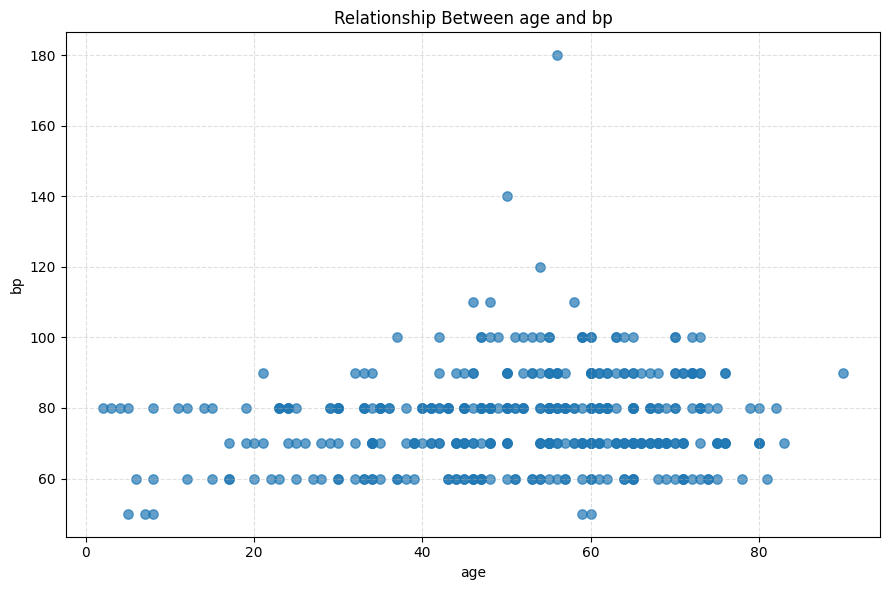

Dataset used: df_encoded_demo
X-axis: age
Y-axis: bp
Number of observations plotted: 400


In [45]:

import pandas as pd
import matplotlib.pyplot as plt

# Find the existing processed DataFrame
data = None
data_name = None

for name in [
    "df_encoded_demo", "df_processed", "df_cleaned",
    "df_encoded", "df_scaled", "df_binned", "df"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        data = obj.copy()
        data_name = name
        break

if data is None:
    raise NameError(
        "Processed dataset not found. Run the earlier data "
        "preprocessing cells before running this graph."
    )

# Select numerical features
numeric_data = data.select_dtypes(include="number")
numeric_data = numeric_data.dropna(axis=1, how="all")

# Keep features with at least two distinct values
numeric_data = numeric_data.loc[
    :, numeric_data.nunique(dropna=True) > 1
]

if numeric_data.shape[1] < 2:
    raise ValueError("At least two numerical features are required.")

# Select the first two numerical features
x_column = numeric_data.columns[0]
y_column = numeric_data.columns[1]

plot_data = numeric_data[[x_column, y_column]].dropna()

# Create scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    plot_data[x_column],
    plot_data[y_column],
    alpha=0.7,
    s=45
)

plt.title(f"Relationship Between {x_column} and {y_column}")
plt.xlabel(x_column)
plt.ylabel(y_column)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Dataset used:", data_name)
print("X-axis:", x_column)
print("Y-axis:", y_column)
print("Number of observations plotted:", len(plot_data))


**Description: Scatter Plot**

1. A scatter plot visualizes the relationship between two numerical features.
2. The X-axis represents one feature, while the Y-axis represents the other.
3. Each dot represents one observation in the dataset.
4. Upward and downward patterns suggest positive and negative relationships, respectively.
5. We use it to explore feature relationships, clusters, and unusual observations.

## 8.5 Bar Graph: Frequency of Categorical Features

### Purpose

The purpose of a bar graph is to compare the frequency of different categories in a dataset. It helps us understand how observations are distributed across categories and identify which categories occur most or least frequently.

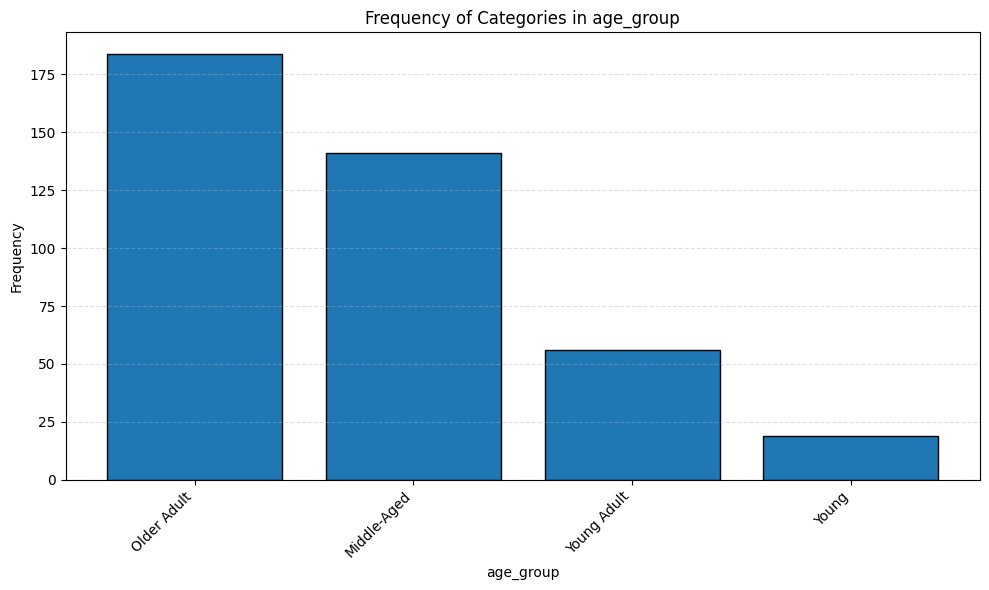

Dataset used: df_encoded_demo
Categorical feature: age_group

Category frequencies:
age_group
Older Adult    184
Middle-Aged    141
Young Adult     56
Young           19
Name: count, dtype: int64


In [46]:

import pandas as pd
import matplotlib.pyplot as plt

# Find the existing DataFrame
data = None
data_name = None

for name in [
    "df_encoded_demo", "df_processed", "df_cleaned",
    "df_encoded", "df_scaled", "df_binned", "df"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        data = obj.copy()
        data_name = name
        break

if data is None:
    raise NameError(
        "Processed dataset not found. Run the earlier "
        "data preprocessing cells before this graph."
    )

# Find categorical columns
categorical_columns = data.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if not categorical_columns:
    raise ValueError(
        "No categorical columns found. If categorical features "
        "were encoded numerically, use the original categorical "
        "column or a saved pre-encoding dataset."
    )

# Select the first categorical column
category_column = categorical_columns[0]

# Calculate category frequencies
category_counts = data[category_column].value_counts(
    dropna=False
)

# Create bar graph
plt.figure(figsize=(10, 6))

plt.bar(
    category_counts.index.astype(str),
    category_counts.values,
    edgecolor="black"
)

plt.title(f"Frequency of Categories in {category_column}")
plt.xlabel(category_column)
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Dataset used:", data_name)
print("Categorical feature:", category_column)
print("\nCategory frequencies:")
print(category_counts)


**Description: Bar Graph for Category Frequency**

1. A bar graph compares the frequency of different categories in a dataset.
2. The X-axis shows the categories, and the Y-axis shows the number of observations.
3. Each bar represents one category, with its height indicating its frequency.
4. It helps identify the most frequent and least frequent categories.
5. We use it to understand category distribution and detect possible class imbalance.

## 8.6 Conclusion: Data Visualization Using Matplotlib

In this assignment, we used Matplotlib to visualize our dataset using five different types of graphs. These visualizations helped us understand the distribution of data, identify potential outliers, analyze relationships between numerical features, compare categorical values, and evaluate the effects of feature engineering techniques. Data visualization is an important step in understanding and preparing data for machine-learning algorithms.

**Key Observations:**

1. **Histogram:** It helped us understand the distribution of numerical features and compare the original BGR values with the log-transformed values to observe changes in skewness.

2. **Box Plot:** It helped us visualize the spread of numerical features, understand the median and quartiles, and identify potential outliers in the dataset.

3. **Correlation Heatmap:** It helped us understand the strength and direction of relationships between numerical features and identify potentially redundant features.

4. **Scatter Plot:** It helped us visualize the relationship between two numerical features and identify patterns, trends, clusters, and unusual observations.

5. **Bar Graph:** It helped us compare the frequencies of different categories and understand the distribution of categorical data.

**Overall Conclusion:**

These five visualizations improved our understanding of the dataset after data cleaning and feature engineering. They helped us explore important patterns and relationships, supporting better decisions during data preprocessing, feature selection, and machine-learning model development.

# 9. Data Visualization Using Seaborn   
Seaborn is a Python library used to create statistical graphs. It is built on Matplotlib and works directly with Pandas DataFrames. It helps us understand data distributions, relationships between features, differences between categories, and potential outliers.
In this section, we use Seaborn to explore the cleaned CKD dataset through violin plots, KDE plots, line plots, regression plots, and bar plots.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Copy the cleaned CKD dataset
plot_df = df_encoded_demo.copy()

# Convert target values into readable labels
plot_df["Condition"] = plot_df["class"].map({
    0: "Non-CKD",
    1: "CKD"
})

condition_order = ["Non-CKD", "CKD"]

## 9.1 Violin Plot: Hemoglobin Distribution by CKD Status

### Purpose
To compare the distribution, spread, and central values of hemoglobin between CKD and Non-CKD patient groups.

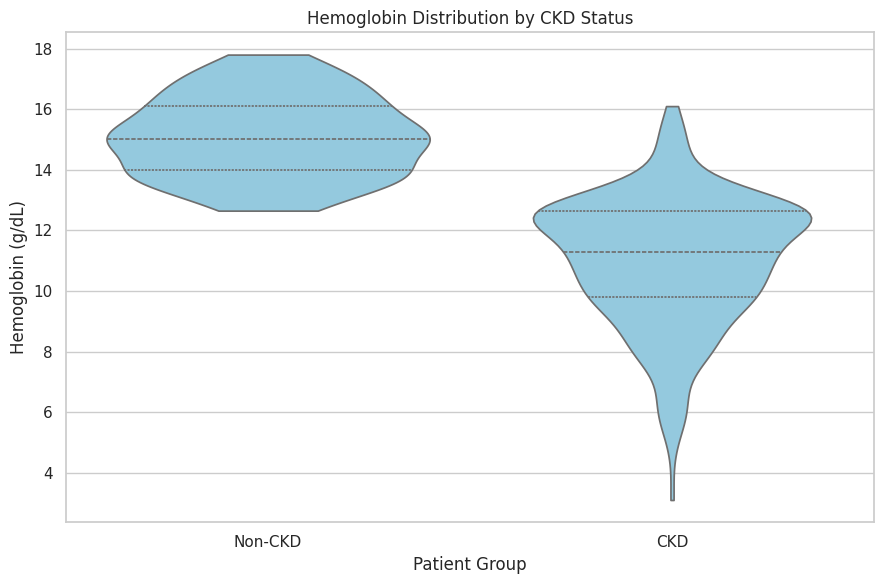

In [48]:
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=plot_df,
    x="Condition",
    y="hemo",
    order=condition_order,
    inner="quart",
    cut=0,
    color="skyblue"
)

plt.title("Hemoglobin Distribution by CKD Status")
plt.xlabel("Patient Group")
plt.ylabel("Hemoglobin (g/dL)")
plt.tight_layout()
plt.show()

**Description / Why to Use**
1. A violin plot shows how numerical values are distributed within different categories.
2. Wider portions indicate a greater concentration of values around that level.
3. The internal lines represent the median and quartiles.
4. It helps compare the spread and shape of hemoglobin values between the two groups.
5. We use it because an average alone cannot show whether values are tightly grouped or widely distributed.

##9.2 KDE Plot: Blood Glucose Distribution by CKD Status

###Purpose
To visualize and compare the smooth distribution of random blood glucose levels in CKD and Non-CKD patient groups.

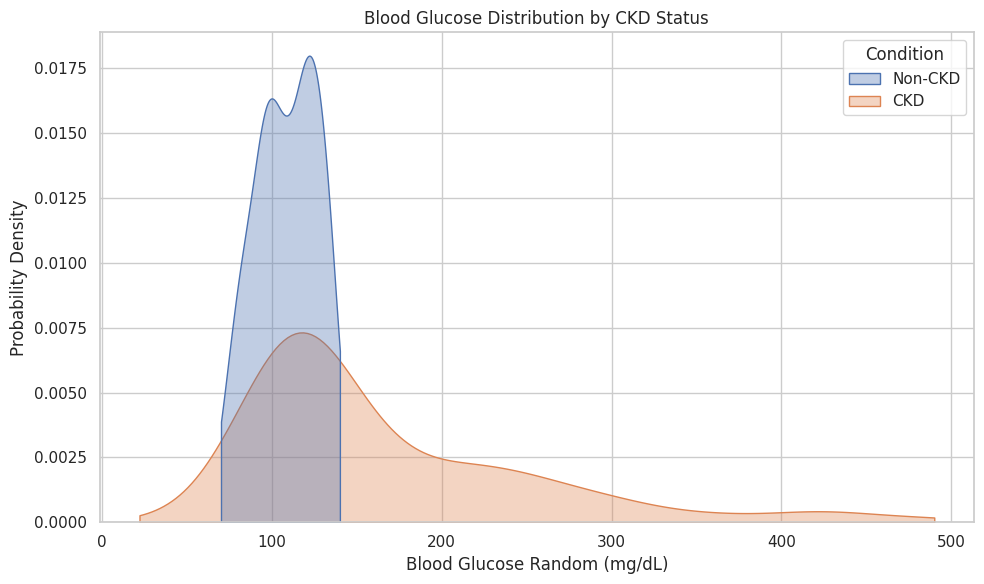

In [49]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=plot_df,
    x="bgr",
    hue="Condition",
    hue_order=condition_order,
    fill=True,
    common_norm=False,
    alpha=0.35,
    cut=0
)

plt.title("Blood Glucose Distribution by CKD Status")
plt.xlabel("Blood Glucose Random (mg/dL)")
plt.ylabel("Probability Density")
plt.tight_layout()
plt.show()

**Description / Why to Use**
1. KDE stands for Kernel Density Estimation and represents a distribution using a smooth curve.
2. Peaks indicate blood glucose ranges where values are more concentrated.
3. The curve’s shape helps reveal skewness and the spread of values.
4. Overlapping curves help compare similarities and differences between the two groups.
5. We use common_norm=False to normalize each group separately, making their distribution shapes easier to compare.

##9.3 Line Plot: Average Hemoglobin Across Age Groups

###Purpose
To examine how average hemoglobin differs across ordered age groups and compare the pattern between CKD and Non-CKD records.

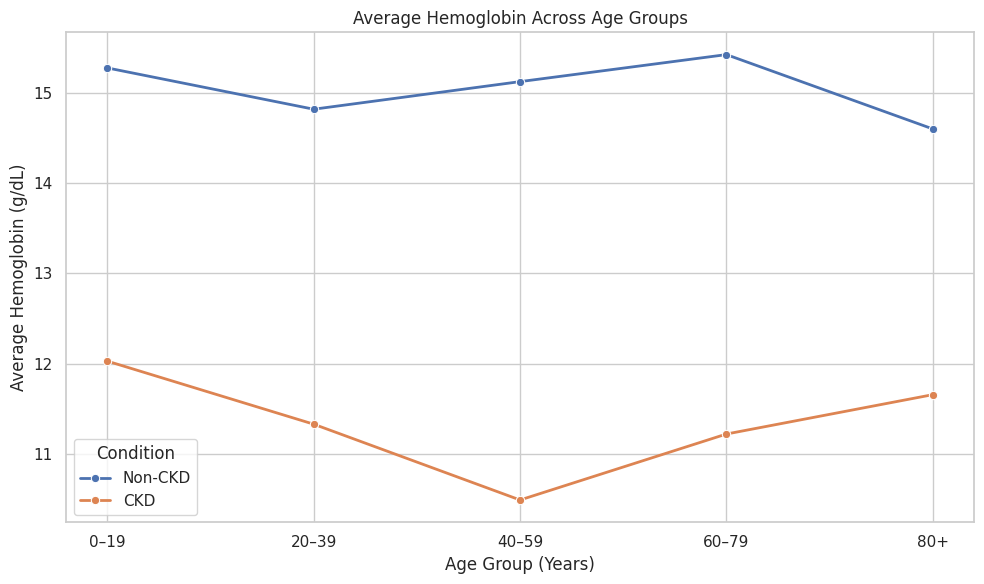

In [50]:
# Create age groups
age_labels = ["0–19", "20–39", "40–59", "60–79", "80+"]

plot_df["Age_Group_Plot"] = pd.cut(
    plot_df["age"],
    bins=[0, 20, 40, 60, 80, np.inf],
    labels=age_labels,
    right=False
)

# Calculate average hemoglobin for each group
age_summary = (
    plot_df.groupby(
        ["Age_Group_Plot", "Condition"],
        observed=True,
        as_index=False
    )["hemo"]
    .mean()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=age_summary,
    x="Age_Group_Plot",
    y="hemo",
    hue="Condition",
    hue_order=condition_order,
    marker="o",
    linewidth=2,
    estimator=None,
    sort=False
)

plt.title("Average Hemoglobin Across Age Groups")
plt.xlabel("Age Group (Years)")
plt.ylabel("Average Hemoglobin (g/dL)")
plt.tight_layout()
plt.show()

**Description / Why to Use**
1. A line plot displays patterns across an ordered variable, such as age groups.
2. Each point represents the average hemoglobin for one age group and patient condition.
3. Connecting the points makes increases, decreases, and fluctuations easier to identify.
4. Separate lines allow a direct comparison between CKD and Non-CKD groups.
5. These lines compare different patient groups; they do not represent the same patients being followed over time.

###9.4 Regression Plot: Relationship Between Age and Hemoglobin

##Purpose
To explore the overall linear relationship between patient age and hemoglobin using individual observations and a fitted regression line.

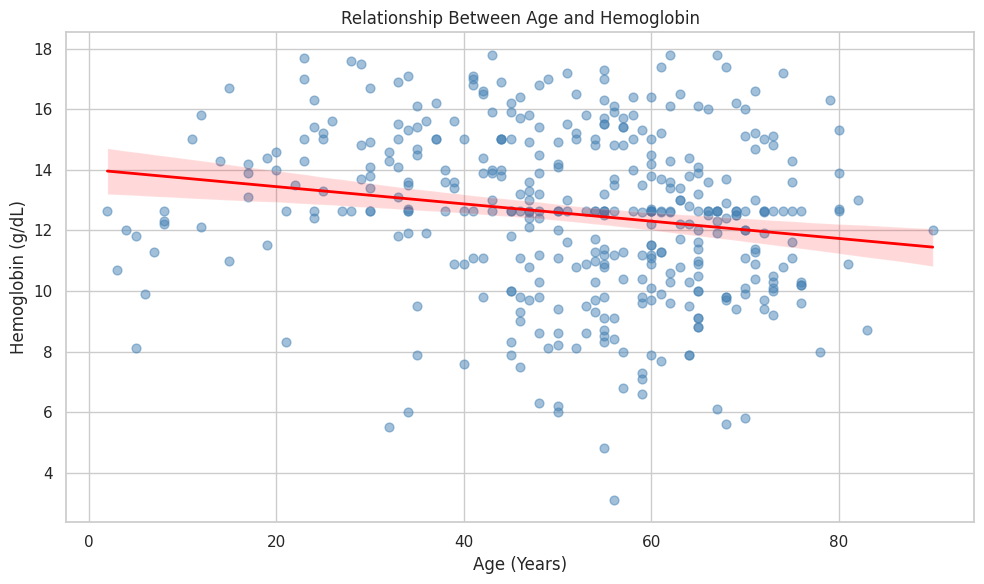

In [51]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=plot_df,
    x="age",
    y="hemo",
    ci=95,
    seed=42,
    scatter_kws={
        "alpha": 0.5,
        "s": 40,
        "color": "steelblue"
    },
    line_kws={
        "color": "red",
        "linewidth": 2
    }
)

plt.title("Relationship Between Age and Hemoglobin")
plt.xlabel("Age (Years)")
plt.ylabel("Hemoglobin (g/dL)")
plt.tight_layout()
plt.show()

**Description / Why to Use**
1. A regression plot combines individual data points with a fitted line.
2. Each dot shows the age and hemoglobin values of one record.
3. An upward or downward line indicates the direction of the estimated linear association.
4. The shaded region shows the 95% confidence interval for the estimated regression line.
5. We use it to explore relationships between numerical features; it does not establish causation or evaluate the CKD prediction model.

##9.5 Bar Plot: Average Hemoglobin by CKD Status

###Purpose
To compare the average hemoglobin levels of CKD and Non-CKD patient groups using bar heights.

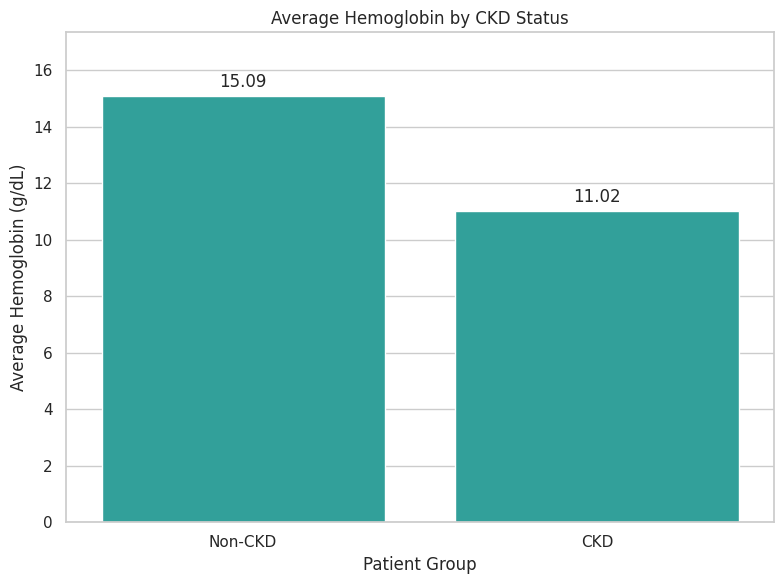

In [52]:
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=plot_df,
    x="Condition",
    y="hemo",
    order=condition_order,
    estimator="mean",
    errorbar=None,
    color="lightseagreen"
)

# Add the calculated mean above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4
    )

plt.title("Average Hemoglobin by CKD Status")
plt.xlabel("Patient Group")
plt.ylabel("Average Hemoglobin (g/dL)")
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

**Description / Why to Use**
1. A bar plot compares a numerical summary across categories.
2. Here, each bar represents the mean hemoglobin of one patient group.
3. A taller bar indicates a higher average hemoglobin value.
4. Labels above the bars display the calculated averages clearly.
5. We use it for a simple comparison of group averages; use the violin plot to examine the distributions behind those averages.

## 9.6 Conclusion: Data Visualization Using Seaborn

In this assignment, we used Seaborn to visualize our cleaned CKD dataset using five different types of graphs. These visualizations helped us explore feature distributions, compare patient groups, examine patterns across age groups, and understand relationships between numerical features.

**Key Observations:**

1. **Violin Plot:** It helped us compare the distribution, median, quartiles, and spread of hemoglobin values between CKD and Non-CKD patient groups.

2. **KDE Plot:** It helped us compare the smooth distributions of blood glucose levels between patient groups and examine their concentration, spread, and skewness.

3. **Line Plot:** It helped us compare average hemoglobin across ordered age groups and explore differences in patterns between CKD and Non-CKD records.

4. **Regression Plot:** It helped us explore the overall linear relationship between age and hemoglobin using individual observations and a fitted regression line.

5. **Bar Plot:** It helped us compare average hemoglobin levels between CKD and Non-CKD patient groups clearly.

**Overall Conclusion:**

These five visualizations improved our understanding of the dataset after data cleaning and feature engineering. They helped us explore distributions, group differences, and feature relationships, supporting informed decisions during preprocessing, feature selection, and further machine-learning model development.